# Inventory policies – CA_1, FOODS_3

Goal: turn the Phase 1 forecasts into weekly orders and measure stock, service and cost
in a day-by-day replay of 2016-01-04 to 2016-05-22.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(ROOT))

from src.inventory.inputs import build_inputs, draw_lead_times
from src.inventory.policies import replenish_last_week
from src.inventory.simulate import simulate

plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

inputs = build_inputs()
lead_times = draw_lead_times(inputs)
baseline = simulate(inputs, replenish_last_week, lead_times)
baseline.head()

,unique_id,demand_class,sell_price,ds,start_stock,received,demand,sales,lost,end_stock,order,on_order
0,FOODS_3_001_CA_1,intermittent,2.5,2016-01-04,9.0,0.0,1.0,1.0,0.0,8.0,5,5.0
1,FOODS_3_001_CA_1,intermittent,2.5,2016-01-05,8.0,0.0,0.0,0.0,0.0,8.0,0,5.0
2,FOODS_3_001_CA_1,intermittent,2.5,2016-01-06,8.0,0.0,2.0,2.0,0.0,6.0,0,5.0
3,FOODS_3_001_CA_1,intermittent,2.5,2016-01-07,6.0,5.0,0.0,0.0,0.0,11.0,0,0.0
4,FOODS_3_001_CA_1,intermittent,2.5,2016-01-08,11.0,0.0,0.0,0.0,0.0,11.0,0,0.0


## Baseline: reorder last week's sales

In [2]:
scored = baseline[baseline["ds"] >= pd.Timestamp("2016-01-18")]  # skip the 14-day warm-up
by_class = scored.groupby("demand_class")[["demand", "sales", "end_stock"]].mean()
by_class["fill_rate"] = by_class["sales"] / by_class["demand"]
by_class["days_of_stock"] = by_class["end_stock"] / by_class["demand"]
by_class[["fill_rate", "days_of_stock"]].round(3)

,fill_rate,days_of_stock
demand_class,,
erratic,0.906,11.003
intermittent,0.846,10.287
lumpy,0.709,9.452
smooth,0.954,10.069


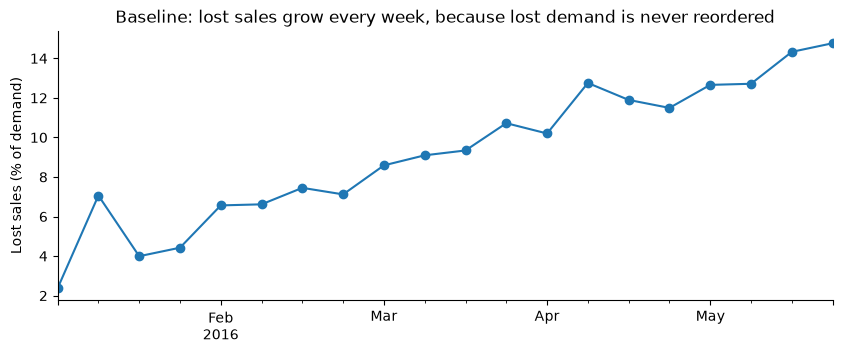

In [3]:
weekly = baseline.groupby(pd.Grouper(key="ds", freq="W-SUN"))[["demand", "lost"]].sum()

ax = (100 * weekly["lost"] / weekly["demand"]).plot(figsize=(10, 3.5), marker="o")
ax.set_title("Baseline: lost sales grow every week, because lost demand is never reordered")
ax.set_ylabel("Lost sales (% of demand)")
ax.set_xlabel("")
plt.show()

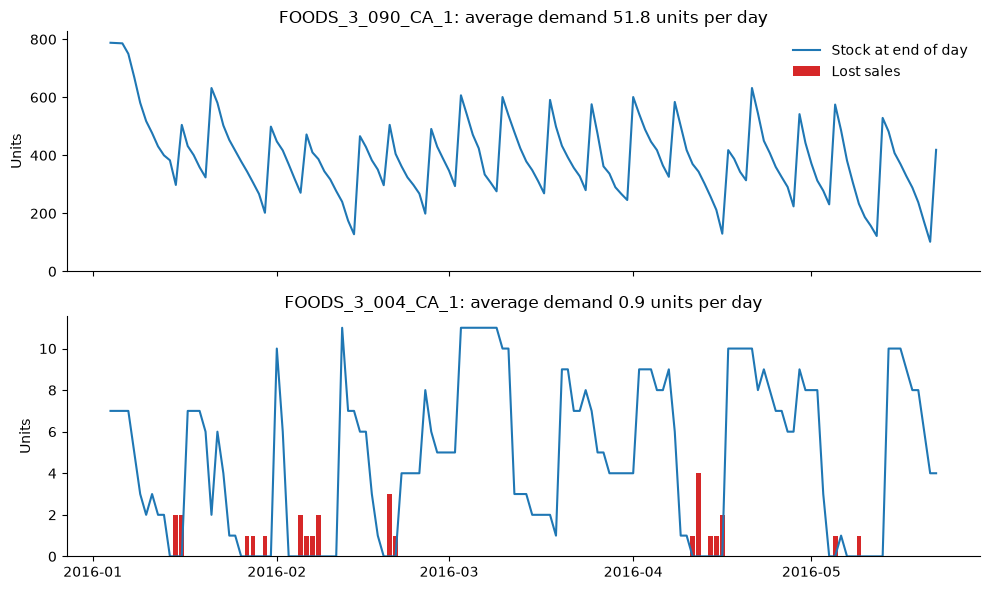

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
for ax, uid in zip(axes, ["FOODS_3_090_CA_1", "FOODS_3_004_CA_1"]):
    g = baseline[baseline["unique_id"] == uid]
    ax.plot(g["ds"], g["end_stock"], label="Stock at end of day")
    ax.bar(g["ds"], g["lost"], color="tab:red", label="Lost sales")
    ax.set_title(f"{uid}: average demand {g['demand'].mean():.1f} units per day")
    ax.set_ylabel("Units")
axes[0].legend(frameon=False)
plt.tight_layout()
plt.show()

In [5]:
from src.inventory.kpis import scorecard
from src.inventory.policies import order_up_to_normal

normal = simulate(inputs, order_up_to_normal, lead_times)

compare = pd.concat(
    {"Baseline": scorecard(baseline), "(R, S) normal": scorecard(normal)}, names=["policy"]
)
compare.round(3)

items  fill_rate  cycle_service  days_of_stock  \
policy                                                                       
Baseline      all           821.0      0.901          0.811         10.244   
              erratic       104.0      0.906          0.819         11.003   
              intermittent  359.0      0.846          0.804         10.287   
              lumpy         184.0      0.709          0.734          9.452   
              smooth        174.0      0.954          0.900         10.069   
(R, S) normal all           821.0      0.902          0.848          7.216   
              erratic       104.0      0.860          0.784          7.026   
              intermittent  359.0      0.937          0.899         10.394   
              lumpy         184.0      0.860          0.837          9.999   
              smooth        174.0      0.918          0.793          5.798   

                            stock_value   orders  holding_cost  ordering_cost  \
policy                                                                          
Baseline      all             58349.463  12291.0      5035.639        12291.0   
              erratic          9813.515   1852.0       846.920         1852.0   
              intermittent    12582.087   4992.0      1085.851         4992.0   
              lumpy            5002.908   2330.0       431.758         2330.0   
              smooth          30950.952   3117.0      2671.110         3117.0   
(R, S) normal all             41676.815  12517.0      3596.766        12517.0   
              erratic          5974.834   1759.0       515.636         1759.0   
              intermittent    12542.141   5231.0      1082.404         5231.0   
              lumpy            5166.312   2441.0       445.860         2441.0   
              smooth          17993.528   3086.0      1552.866         3086.0   

                            lost_sales_cost  total_cost  
policy                                                   
Baseline      all                 18839.583   36166.222  
              erratic              2591.742    5290.662  
              intermittent         5946.627   12024.478  
              lumpy                5228.787    7990.545  
              smooth               5072.427   10860.537  
(R, S) normal all                 20624.490   36738.256  
              erratic              5204.145    7478.781  
              intermittent         2566.428    8879.832  
              lumpy                2277.690    5164.550  
              smooth              10576.227   15215.093

In [6]:
from src.inventory.policies import order_up_to_quantile, order_up_to_quantile_sum

quantile_sum = simulate(inputs, order_up_to_quantile_sum, lead_times)
quantile = simulate(inputs, order_up_to_quantile, lead_times)

compare = pd.concat(
    {
        "Baseline": scorecard(baseline),
        "(R, S) normal": scorecard(normal),
        "(R, S) sum of q95": scorecard(quantile_sum),
        "(R, S) quantile": scorecard(quantile),
    },
    names=["policy"],
)
compare.round(3)

items  fill_rate  cycle_service  \
policy                                                            
Baseline          all           821.0      0.901          0.811   
                  erratic       104.0      0.906          0.819   
                  intermittent  359.0      0.846          0.804   
                  lumpy         184.0      0.709          0.734   
                  smooth        174.0      0.954          0.900   
(R, S) normal     all           821.0      0.902          0.848   
                  erratic       104.0      0.860          0.784   
                  intermittent  359.0      0.937          0.899   
                  lumpy         184.0      0.860          0.837   
                  smooth        174.0      0.918          0.793   
(R, S) sum of q95 all           821.0      0.994          0.995   
                  erratic       104.0      0.986          0.987   
                  intermittent  359.0      0.999          0.999   
                  lumpy         184.0      0.989          0.996   
                  smooth        174.0      0.997          0.990   
(R, S) quantile   all           821.0      0.939          0.916   
                  erratic       104.0      0.912          0.870   
                  intermittent  359.0      0.968          0.951   
                  lumpy         184.0      0.917          0.919   
                  smooth        174.0      0.947          0.867   

                                days_of_stock  stock_value   orders  \
policy                                                                
Baseline          all                  10.244    58349.463  12291.0   
                  erratic              11.003     9813.515   1852.0   
                  intermittent         10.287    12582.087   4992.0   
                  lumpy                 9.452     5002.908   2330.0   
                  smooth               10.069    30950.952   3117.0   
(R, S) normal     all                   7.216    41676.815  12517.0   
                  erratic               7.026     5974.834   1759.0   
                  intermittent         10.394    12542.141   5231.0   
                  lumpy                 9.999     5166.312   2441.0   
                  smooth                5.798    17993.528   3086.0   
(R, S) sum of q95 all                  23.471   136350.968  12603.0   
                  erratic              24.027    21384.151   1676.0   
                  intermittent         33.557    39599.278   5383.0   
                  lumpy                36.358    18950.608   2530.0   
                  smooth               17.645    56416.932   3014.0   
(R, S) quantile   all                   8.923    51491.787  12742.0   
                  erratic               8.910     7751.175   1762.0   
                  intermittent         12.610    14984.955   5362.0   
                  lumpy                13.175     6913.026   2526.0   
                  smooth                6.980    21842.630   3092.0   

                                holding_cost  ordering_cost  lost_sales_cost  \
policy                                                                         
Baseline          all               5035.639        12291.0        18839.583   
                  erratic            846.920         1852.0         2591.742   
                  intermittent      1085.851         4992.0         5946.627   
                  lumpy              431.758         2330.0         5228.787   
                  smooth            2671.110         3117.0         5072.427   
(R, S) normal     all               3596.766        12517.0        20624.490   
                  erratic            515.636         1759.0         5204.145   
                  intermittent      1082.404         5231.0         2566.428   
                  lumpy              445.860         2441.0         2277.690   
                  smooth            1552.866         3086.0        10576.227   
(R, S) sum of q95 all             

In [7]:
from functools import partial

from src.inventory.tuning import tune_z

z_by_class = tune_z(inputs, lead_times)
print(z_by_class)

tuned = simulate(inputs, partial(order_up_to_quantile, z_by_class=z_by_class), lead_times)

TEST_START = pd.Timestamp("2016-04-25")
test_window = pd.concat(
    {
        "Baseline": scorecard(baseline, TEST_START),
        "(R, S) normal": scorecard(normal, TEST_START),
        "(R, S) quantile": scorecard(quantile, TEST_START),
        "(R, S) quantile, tuned z": scorecard(tuned, TEST_START),
    },
    names=["policy"],
)
test_window.round(3)

{'smooth': 3.11, 'erratic': 2.8, 'intermittent': 1.66, 'lumpy': 2.12}


items  fill_rate  cycle_service  \
policy                                                                   
Baseline                 all           821.0      0.864          0.746   
                         erratic       104.0      0.849          0.781   
                         intermittent  359.0      0.801          0.741   
                         lumpy         184.0      0.626          0.625   
                         smooth        174.0      0.945          0.864   
(R, S) normal            all           821.0      0.908          0.857   
                         erratic       104.0      0.821          0.774   
                         intermittent  359.0      0.945          0.907   
                         lumpy         184.0      0.863          0.812   
                         smooth        174.0      0.949          0.849   
(R, S) quantile          all           821.0      0.937          0.918   
                         erratic       104.0      0.872          0.853   
                         intermittent  359.0      0.973          0.955   
                         lumpy         184.0      0.910          0.899   
                         smooth        174.0      0.964          0.899   
(R, S) quantile, tuned z all           821.0      0.964          0.948   
                         erratic       104.0      0.919          0.921   
                         intermittent  359.0      0.974          0.954   
                         lumpy         184.0      0.934          0.931   
                         smooth        174.0      0.988          0.970   

                                       days_of_stock  stock_value  orders  \
policy                                                                      
Baseline                 all                   9.343    57020.226  2814.0   
                         erratic               9.523     9440.440   414.0   
                         intermittent          9.540    12531.475  1168.0   
                         lumpy                 7.626     4763.661   540.0   
                         smooth                9.604    30284.650   692.0   
(R, S) normal            all                   7.132    45032.959  2937.0   
                         erratic               5.851     6141.256   396.0   
                         intermittent         10.608    13547.876  1235.0   
                         lumpy                 9.361     5772.824   616.0   
                         smooth                6.153    19571.004   690.0   
(R, S) quantile          all                   8.602    53992.490  2963.0   
                         erratic               7.484     7792.152   390.0   
                         intermittent         12.429    15744.932  1262.0   
                         lumpy                11.338     7062.382   622.0   
                         smooth                7.323    23393.023   689.0   
(R, S) quantile, tuned z all                  11.935    73454.265  2943.0   
                         erratic              11.422    11723.958   379.0   
                         intermittent         12.506    15835.224  1263.0   
                         lumpy                13.602     8462.823   619.0   
                         smooth               11.608    37432.261   682.0   

                                       holding_cost  ordering_cost  \
policy                                                               
Baseline                 all               1093.539         2814.0   
                         erratic            181.050          414.0   
                         intermittent       240.330         1168.0   
                         lumpy               91.358          540.0   
                         smooth             580.801          692.0   
(R, S) normal            all                863.646         2937.0   
                         erratic            117.778          396.0   
                         intermittent       259.822         1235.0   
               

In [8]:
from src.inventory.policies import reorder_point

batch = simulate(inputs, partial(reorder_point, z_by_class=z_by_class), lead_times)

pd.concat(
    {"(R, S) quantile, tuned z": scorecard(tuned), "(s, S) tuned z": scorecard(batch)},
    names=["policy"],
).round(3)

items  fill_rate  cycle_service  \
policy                                                                   
(R, S) quantile, tuned z all           821.0      0.970          0.950   
                         erratic       104.0      0.956          0.943   
                         intermittent  359.0      0.969          0.952   
                         lumpy         184.0      0.940          0.947   
                         smooth        174.0      0.983          0.955   
(s, S) tuned z           all           821.0      0.987          0.984   
                         erratic       104.0      0.980          0.975   
                         intermittent  359.0      0.991          0.989   
                         lumpy         184.0      0.968          0.982   
                         smooth        174.0      0.993          0.982   

                                       days_of_stock  stock_value   orders  \
policy                                                                       
(R, S) quantile, tuned z all                  12.417    70718.683  12700.0   
                         erratic              13.262    11674.716   1730.0   
                         intermittent         12.686    15074.951   5361.0   
                         lumpy                15.913     8342.306   2536.0   
                         smooth               11.261    35626.710   3073.0   
(s, S) tuned z           all                  23.285   127838.383   3608.0   
                         erratic              24.348    20088.850    584.0   
                         intermittent         29.755    33732.110   1180.0   
                         lumpy                35.042    16854.714    574.0   
                         smooth               18.531    57162.709   1270.0   

                                       holding_cost  ordering_cost  \
policy                                                               
(R, S) quantile, tuned z all               6103.119        12700.0   
                         erratic           1007.544         1730.0   
                         intermittent      1300.989         5361.0   
                         lumpy              719.952         2536.0   
                         smooth            3074.634         3073.0   
(s, S) tuned z           all              11032.628         3608.0   
                         erratic           1733.695          584.0   
                         intermittent      2911.127         1180.0   
                         lumpy             1454.585          574.0   
                         smooth            4933.220         1270.0   

                                       lost_sales_cost  total_cost  
policy                                                              
(R, S) quantile, tuned z all                  5868.600   24671.719  
                         erratic              1543.494    4281.038  
                         intermittent         1319.565    7981.554  
                         lumpy                 772.113    4028.065  
                         smooth               2233.428    8381.062  
(s, S) tuned z           all                  2407.158   17047.786  
                         erratic               680.322    2998.017  
                         intermittent          368.457    4459.584  
                         lumpy                 319.707    2348.292  
                         smooth               1038.672    7241.892

## All policies: service, stock and cost

In [9]:
kpis = pd.read_csv(ROOT / "results" / "inventory_kpis.csv", index_col=["policy", "demand_class"])
cols = [
    "fill_rate",
    "cycle_service",
    "days_of_stock",
    "stock_value",
    "orders",
    "holding_cost",
    "ordering_cost",
    "lost_sales_cost",
    "total_cost",
]
kpis.xs("all", level="demand_class")[cols].round(3)

,fill_rate,cycle_service,days_of_stock,stock_value,orders,holding_cost,ordering_cost,lost_sales_cost,total_cost
policy,,,,,,,,,
Baseline,0.901,0.810,10.244,58349.463,12291.0,5035.639,12291.0,18839.583,36166.222
"(R, S) normal",0.902,0.848,7.216,41676.815,12517.0,3596.766,12517.0,20624.490,36738.256
"(R, S) sum of q95",0.994,0.995,23.472,136350.968,12603.0,11767.275,12603.0,951.852,25322.127
"(R, S) quantile",0.939,0.916,8.923,51491.787,12742.0,4443.812,12742.0,12199.869,29385.681
"(R, S) quantile, tuned z",0.970,0.950,12.417,70718.683,12700.0,6103.119,12700.0,5868.600,24671.719
"(s, S) tuned z",0.987,0.984,23.285,127838.383,3608.0,11032.628,3608.0,2407.158,17047.786


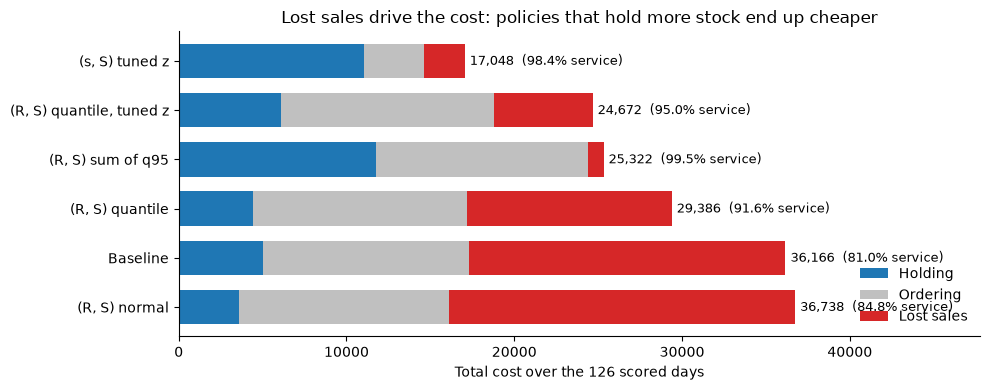

In [10]:
overall = kpis.xs("all", level="demand_class")
costs = overall[["holding_cost", "ordering_cost", "lost_sales_cost"]].rename(
    columns={
        "holding_cost": "Holding",
        "ordering_cost": "Ordering",
        "lost_sales_cost": "Lost sales",
    }
)
costs = costs.loc[costs.sum(axis=1).sort_values(ascending=False).index]

ax = costs.plot.barh(
    stacked=True, figsize=(10, 4), color=["tab:blue", "silver", "tab:red"], width=0.7
)
for i, (name, total) in enumerate(costs.sum(axis=1).items()):
    service = overall.loc[name, "cycle_service"]
    ax.text(total + 300, i, f"{total:,.0f}  ({service:.1%} service)", va="center", fontsize=9)
ax.set_xlim(0, costs.sum(axis=1).max() * 1.3)
ax.set_xlabel("Total cost over the 126 scored days")
ax.set_ylabel("")
ax.set_title("Lost sales drive the cost: policies that hold more stock end up cheaper")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.show()

## Stock against service: the fair comparison

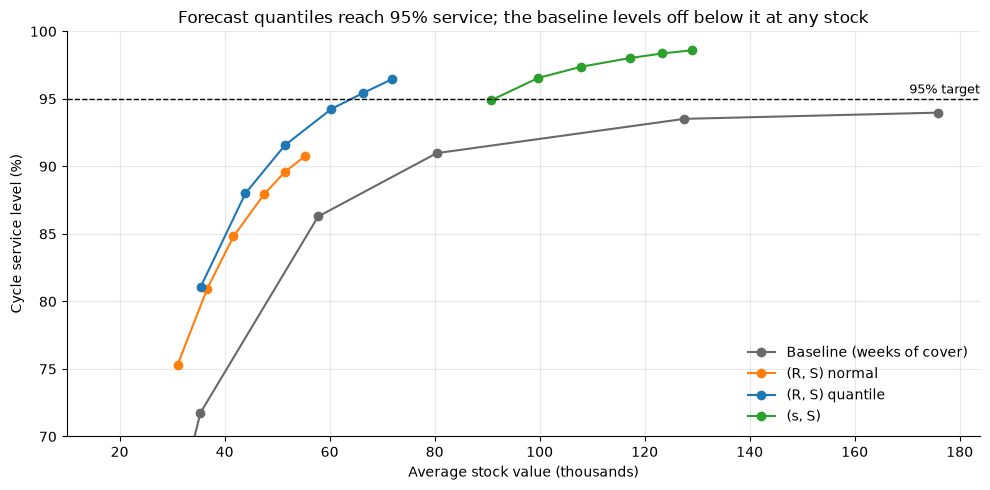

In [11]:
sweep = pd.read_csv(ROOT / "results" / "inventory_sweep.csv")
base = sweep[sweep["scenario"] == "base"]

STYLE = {
    "Baseline (weeks of cover)": "dimgray",
    "(R, S) normal": "tab:orange",
    "(R, S) quantile": "tab:blue",
    "(s, S)": "tab:green",
}
fig, ax = plt.subplots(figsize=(10, 5))
for name, color in STYLE.items():
    curve = base[base["policy"] == name].sort_values("stock_value")
    ax.plot(
        curve["stock_value"] / 1000,
        curve["cycle_service"] * 100,
        marker="o",
        color=color,
        label=name,
    )
ax.axhline(95, color="black", linestyle="--", linewidth=1)
ax.text(ax.get_xlim()[1], 95.4, "95% target", ha="right", fontsize=9)
ax.set_xlabel("Average stock value (thousands)")
ax.set_ylabel("Cycle service level (%)")
ax.set_ylim(70, 100)
ax.grid(alpha=0.3)
ax.set_title("Forecast quantiles reach 95% service; the baseline levels off below it at any stock")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.show()

In [12]:
from src.inventory.sweep import stock_at_service

rows = []
for target in (0.90, 0.95):
    for name, curve in base.groupby("policy"):
        rows.append(
            {"target": target, "policy": name, "stock_value": stock_at_service(curve, target)}
        )
needed = pd.DataFrame(rows).pivot(index="policy", columns="target", values="stock_value")
needed.round(0)

target,0.90,0.95
policy,,
"(R, S) normal",52816.0,NaN
"(R, S) quantile",48177.0,64170.0
"(s, S)",NaN,91313.0
Baseline (weeks of cover),75677.0,NaN


In [13]:
best = sweep.loc[sweep.groupby(["scenario", "policy"])["total_cost"].idxmin()]
best.pivot(index="policy", columns="scenario", values="total_cost").round(0)

scenario,base,holding 15%,holding 35%,lost sales 10%,lost sales 50%,order cost 20
policy,,,,,,
"(R, S) normal",30702.0,28795.0,32610.0,21745.0,39660.0,268164.0
"(R, S) quantile",24970.0,22486.0,27455.0,20889.0,29001.0,266536.0
"(s, S)",17430.0,12566.0,21328.0,14397.0,19217.0,43838.0
Baseline (weeks of cover),23737.0,20520.0,26512.0,17589.0,29537.0,148548.0


In [14]:
fig.savefig(ROOT / "docs" / "inventory_tradeoff.png", dpi=150, bbox_inches="tight")

## Findings

1. **Forecast quantiles save capital at equal service.** For 90% cycle service the (R, S) policy set
   from calibrated quantiles needs 48k of stock, against 76k for a weeks-of-cover rule (−36%) and
   53k for the textbook normal formula (−9%).
2. **The baseline cannot reach 95% at any stock level.** It levels off at 94%: an item that sells
   nothing for a week is never reordered, because lost sales are invisible in sales data. The quantile
   policy reaches 95% with 64k.
3. **The textbook safety stock misses its target.** Promised 95%, delivered 85%: the forecast mean
   is biased low and the standard deviation of censored sales understates demand variability.
4. **(s, S) is the cheapest policy in every cost scenario** (17.4k vs 23.7k for the best baseline,
   −27%). It cuts orders by 72%, and its batches also lower lost sales.
5. **Honest negative:** on total cost the weekly (R, S) quantile policy does not beat the best
   baseline setting (25.0k vs 23.7k). Holding stock is cheap here (0.5% of price per week against
   30% for a lost sale), so the forecast's gain shows up as capital, not cost.
6. **The 95% target is too low for these costs.** Every forecast policy gets cheaper up to the
   highest service tested (99.5%); the economic service level is closer to 98–99%.